# 03 · Enfoque bayesiano y análisis por segmentos

**Objetivo:** complementar el análisis del notebook 02 con dos preguntas distintas:

1. **Enfoque bayesiano:** ¿cuál es la probabilidad de que un email supere a otro?, y ¿cuánto se perdería si se elige el equivocado? Esto responde de forma más directa a la pregunta que se hace un equipo de marketing que el p-valor.
2. **Segmentos (exploratorio):** ¿el efecto de cada email cambia según el tipo de cliente?

**Conceptos bayesianos que se usan**
- **A priori (prior):** lo que se supone sobre la tasa antes de ver los datos. Aquí se usa una distribución beta; la uniforme `Beta(1, 1)` considera todas las tasas igualmente plausibles.
- **A posteriori (posterior):** lo que se sabe sobre la tasa después de ver los datos. Con una beta como prior y datos de éxitos y fracasos, la posterior también es una beta, de cálculo exacto.
- **Intervalo de credibilidad del 95 %:** rango que contiene el valor verdadero con probabilidad 95 %, *dado lo observado y el prior*. A diferencia del intervalo de confianza, se interpreta de forma directa.
- **Probabilidad de superioridad:** probabilidad, según la posterior, de que un grupo tenga una tasa mayor que otro.
- **Pérdida esperada:** cuánto se pierde en promedio, en puntos porcentuales de conversión, si se elige una opción y resulta que la otra era mejor.

Frecuentistas y bayesianos responden preguntas distintas: los p-valores y los intervalos de confianza describen el comportamiento de un procedimiento si se repitiera el experimento muchas veces, y la posterior describe la incertidumbre sobre el parámetro dados los datos. Con tantos clientes por grupo, se espera que ambos enfoques lleguen a conclusiones parecidas.

## 1. Setup y datos

Se importan las librerías, las funciones de `src/ab.py` (incluidas el bootstrap bayesiano y la prueba de heterogeneidad) y la carga de datos de `src/data.py`. Se fija la semilla (42) para que las simulaciones sean reproducibles.

In [1]:
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

from src.data import load_hillstrom, prepare, GRUPOS
from src.ab import (
    compare_proportions, holm_adjust, bayesian_bootstrap_mean, heterogeneity_test,
)

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.dpi"] = 110
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)

df = prepare(load_hillstrom())
n_grupo = df["grupo"].value_counts().reindex(GRUPOS)

COMPARACIONES = [("hombres", "control"), ("mujeres", "control"), ("hombres", "mujeres")]
ETIQUETA = {c: f"{c[0]} − {c[1]}" for c in COMPARACIONES}
N_SIM = 200_000  # simulaciones desde las distribuciones posteriores

## 2. Conversión: posterior de la tasa de cada grupo

Con un prior `Beta(1, 1)`, la posterior de la tasa de conversión de un grupo con `x` compras entre `n` clientes es `Beta(1 + x, 1 + n − x)`. Se muestran la media y el intervalo de credibilidad del 95 % de cada grupo.

In [2]:
PRIOR = (1, 1)

def posterior_tasas(metrica, prior=PRIOR, n_sim=N_SIM):
    x = df.groupby("grupo", observed=True)[metrica].sum()
    n = df.groupby("grupo", observed=True)[metrica].size()
    return {g: stats.beta(prior[0] + x[g], prior[1] + n[g] - x[g]).rvs(n_sim, random_state=rng) for g in GRUPOS}

sim_conv = posterior_tasas("conversion")
tabla_post = pd.DataFrame({
    g: {"media_%": 100 * s.mean(), "ic_bajo_%": 100 * np.percentile(s, 2.5), "ic_alto_%": 100 * np.percentile(s, 97.5)}
    for g, s in sim_conv.items()
}).T
tabla_post.round(4)

,media_%,ic_bajo_%,ic_alto_%
control,0.5772,0.4797,0.6837
hombres,1.2574,1.1122,1.4112
mujeres,0.8884,0.7668,1.0189


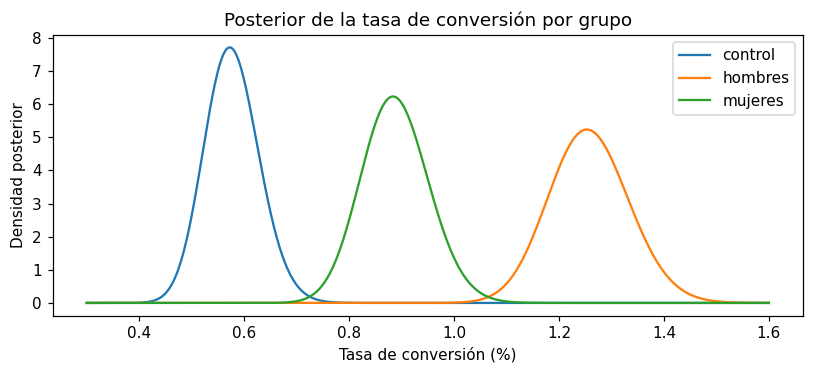

In [3]:
x_plot = np.linspace(0.003, 0.016, 500)
x_ev = df.groupby("grupo", observed=True)["conversion"].sum()

fig, ax = plt.subplots(figsize=(7.5, 3.5))
for g in GRUPOS:
    d = stats.beta(PRIOR[0] + x_ev[g], PRIOR[1] + n_grupo[g] - x_ev[g])
    ax.plot(100 * x_plot, d.pdf(x_plot) / 100, label=g)
ax.set_xlabel("Tasa de conversión (%)")
ax.set_ylabel("Densidad posterior")
ax.set_title("Posterior de la tasa de conversión por grupo")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Comparaciones entre grupos

Se simulan 200.000 valores de cada posterior y se comparan de a pares (como los grupos son independientes, se puede restar directamente). Para cada comparación se reporta:

- la **mediana** de la diferencia y su **intervalo de credibilidad del 95 %**, en puntos porcentuales;
- la **probabilidad de superioridad** (qué tan probable es que la diferencia sea mayor que 0);
- la probabilidad de que la diferencia supere un **umbral de relevancia práctica**: se usa el efecto mínimo detectable del notebook 02 (0,22 pp), que se toma como la diferencia mínima que vale la pena considerar;
- la **pérdida esperada** de elegir cada opción: cuántos puntos porcentuales de conversión se pierden, en promedio, si se elige esa opción y la otra era en realidad mejor.

In [4]:
UMBRAL_PP = 0.22  # diferencia mínima de interés (efecto mínimo detectable del notebook 02)

def comparar_bayes(sim, nombre_metrica):
    filas = []
    for a, b in COMPARACIONES:
        d = 100 * (sim[a] - sim[b])  # en pp
        filas.append({
            "métrica": nombre_metrica,
            "comparación": ETIQUETA[(a, b)],
            "mediana_dif_pp": np.median(d),
            "ic_bajo_pp": np.percentile(d, 2.5),
            "ic_alto_pp": np.percentile(d, 97.5),
            "P(dif > 0)": (d > 0).mean(),
            f"P(dif > {UMBRAL_PP} pp)": (d > UMBRAL_PP).mean(),
            "pérdida_esperada_si_elijo_a_pp": np.maximum(-d, 0).mean(),
            "pérdida_esperada_si_elijo_b_pp": np.maximum(d, 0).mean(),
        })
    return pd.DataFrame(filas)

bayes_conv = comparar_bayes(sim_conv, "conversion")
bayes_conv.round(5)

,métrica,comparación,mediana_dif_pp,ic_bajo_pp,ic_alto_pp,P(dif > 0),P(dif > 0.22 pp),pérdida_esperada_si_elijo_a_pp,pérdida_esperada_si_elijo_b_pp
0,conversion,hombres − control,0.67961,0.50029,0.86223,1.00000,1.00000,0.0,0.68013
1,conversion,mujeres − control,0.31084,0.14935,0.47492,0.99988,0.86532,0.0,0.31121
2,conversion,hombres − mujeres,0.36885,0.17396,0.56575,0.99992,0.93178,0.0,0.36893


**Cómo leer la tabla:** en cada fila, `a` es el primer grupo de la comparación y `b` el segundo. `pérdida_esperada_si_elijo_a_pp` es lo que se pierde, en promedio, si se elige `a` y en realidad `b` es mejor; una pérdida cercana a cero indica que elegir esa opción prácticamente no tiene riesgo.

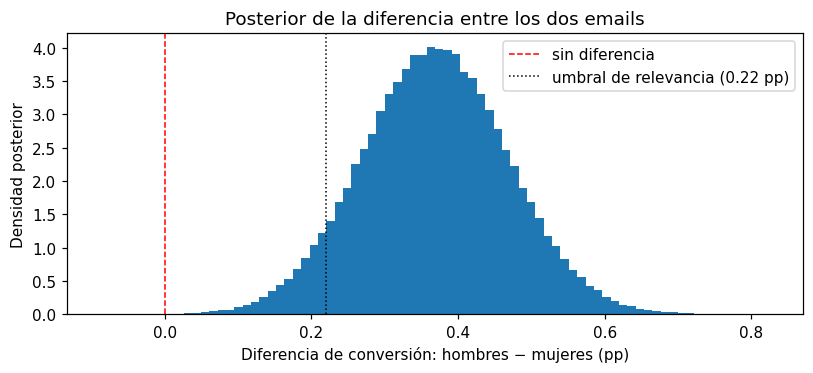

In [5]:
d_hm = 100 * (sim_conv["hombres"] - sim_conv["mujeres"])

fig, ax = plt.subplots(figsize=(7.5, 3.5))
ax.hist(d_hm, bins=80, density=True)
ax.axvline(0, color="red", linestyle="--", linewidth=1, label="sin diferencia")
ax.axvline(UMBRAL_PP, color="black", linestyle=":", linewidth=1, label=f"umbral de relevancia ({UMBRAL_PP} pp)")
ax.set_xlabel("Diferencia de conversión: hombres − mujeres (pp)")
ax.set_ylabel("Densidad posterior")
ax.set_title("Posterior de la diferencia entre los dos emails")
ax.legend()
plt.tight_layout()
plt.show()

### 3.1 Sensibilidad al prior

Se repite la comparación entre emails con tres priors distintos para ver cuánto influye esa elección: uno uniforme, el de Jeffreys `Beta(0,5; 0,5)` y uno informativo centrado en una tasa de 0,6 %, con un peso equivalente a 1.000 clientes, `Beta(6, 994)`. Con 21.000 clientes por grupo, se espera que los datos dominen y el prior importe poco.

In [6]:
priors = {"uniforme Beta(1, 1)": (1, 1), "Jeffreys Beta(0,5; 0,5)": (0.5, 0.5), "informativo Beta(6, 994)": (6, 994)}
filas = []
for nombre, pr in priors.items():
    s = posterior_tasas("conversion", prior=pr, n_sim=100_000)
    d = 100 * (s["hombres"] - s["mujeres"])
    dc = 100 * (s["hombres"] - s["control"])
    filas.append({
        "prior": nombre,
        "mediana hombres − mujeres (pp)": np.median(d),
        "P(hombres > mujeres)": (d > 0).mean(),
        "mediana hombres − control (pp)": np.median(dc),
    })
pd.DataFrame(filas).round(4)

,prior,mediana hombres − mujeres (pp),P(hombres > mujeres),mediana hombres − control (pp)
0,"uniforme Beta(1, 1)",0.3691,1.0000,0.6803
1,"Jeffreys Beta(0,5; 0,5)",0.3692,0.9999,0.6800
2,"informativo Beta(6, 994)",0.3530,0.9999,0.6501


## 4. Visita (secundaria)

La misma comparación para la visita al sitio, con el prior uniforme.

In [7]:
sim_visit = posterior_tasas("visit")
bayes_visit = comparar_bayes(sim_visit, "visit")
bayes_visit.round(5)

,métrica,comparación,mediana_dif_pp,ic_bajo_pp,ic_alto_pp,P(dif > 0),P(dif > 0.22 pp),pérdida_esperada_si_elijo_a_pp,pérdida_esperada_si_elijo_b_pp
0,visit,hombres − control,7.65649,6.99407,8.32043,1.0,1.0,0.0,7.6576
1,visit,mujeres − control,4.52293,3.88787,5.15707,1.0,1.0,0.0,4.5229
2,visit,hombres − mujeres,3.13514,2.42928,3.83983,1.0,1.0,0.0,3.1347


## 5. Gasto por cliente: bootstrap bayesiano

El gasto no se puede modelar bien con una distribución estándar (99 % de ceros y una cola larga). El **bootstrap bayesiano** evita suponer una forma: cada cliente recibe un peso aleatorio (de una distribución de Dirichlet) y se calcula la media ponderada del gasto. Repetir esto muchas veces da una distribución posterior de la media sin suponer normalidad. Es la versión bayesiana del bootstrap del notebook 02, y se espera que dé resultados similares.

In [8]:
gasto = {g: df.loc[df.grupo == g, "spend"].to_numpy() for g in GRUPOS}
sim_gasto = {g: bayesian_bootstrap_mean(gasto[g], 100_000, rng) for g in GRUPOS}

filas = []
for a, b in COMPARACIONES:
    d = sim_gasto[a] - sim_gasto[b]
    filas.append({
        "comparación": ETIQUETA[(a, b)],
        "mediana_dif_USD": np.median(d),
        "ic_bajo": np.percentile(d, 2.5),
        "ic_alto": np.percentile(d, 97.5),
        "P(dif > 0)": (d > 0).mean(),
        "pérdida_esperada_si_elijo_a_USD": np.maximum(-d, 0).mean(),
        "pérdida_esperada_si_elijo_b_USD": np.maximum(d, 0).mean(),
    })
bayes_gasto = pd.DataFrame(filas)
bayes_gasto.round(4)

,comparación,mediana_dif_USD,ic_bajo,ic_alto,P(dif > 0),pérdida_esperada_si_elijo_a_USD,pérdida_esperada_si_elijo_b_USD
0,hombres − control,0.7672,0.4891,1.0597,1.0000,0.0000,0.7693
1,mujeres − control,0.4230,0.1688,0.6853,0.9995,0.0000,0.4242
2,hombres − mujeres,0.3441,0.0331,0.6622,0.9850,0.0009,0.3460


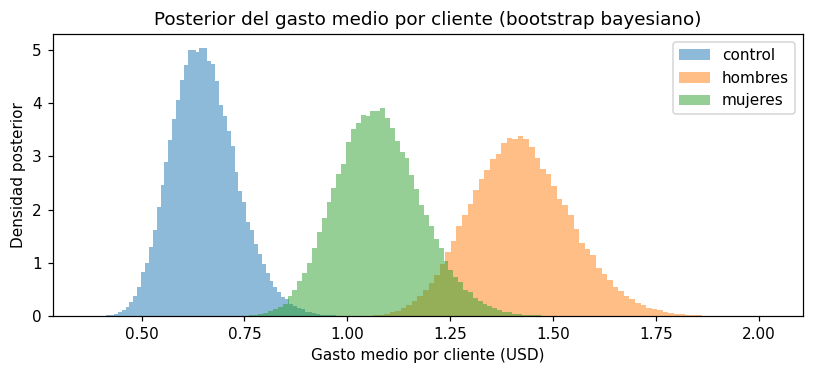

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 3.5))
for g in GRUPOS:
    ax.hist(sim_gasto[g], bins=80, density=True, alpha=0.5, label=g)
ax.set_xlabel("Gasto medio por cliente (USD)")
ax.set_ylabel("Densidad posterior")
ax.set_title("Posterior del gasto medio por cliente (bootstrap bayesiano)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. ¿El efecto cambia según el tipo de cliente? (exploratorio)

Se compara el efecto de cada email en distintos segmentos definidos con variables medidas **antes** del experimento: recencia (meses desde la última compra, en tramos), segmento de historial de gasto, zona, si es cliente nuevo, canal de compra y afinidad (si en el último año compró productos de hombres, de mujeres o de ambos; en este dataset no hay clientes que no hayan comprado ninguno de los dos tipos).

**Advertencias:**
- Este análisis es **exploratorio**: sirve para generar hipótesis, no para confirmarlas. Mirar muchos segmentos aumenta la probabilidad de encontrar diferencias que son solo azar.
- La conversión es un evento raro, así que dentro de cada segmento hay pocas compras y las estimaciones son imprecisas: los intervalos son anchos.
- Para evaluar si el efecto realmente varía entre los segmentos de una variable, se usa la **prueba Q de Cochran**, que compara el efecto de cada segmento con el efecto común. Un p-valor bajo indica que el efecto no es el mismo en todos los segmentos. Esta prueba tiene poca potencia con eventos raros, por lo que un p-valor alto no demuestra que el efecto sea homogéneo. Se corrige por comparaciones múltiples con Holm.

In [10]:
seg = df.copy()
seg["recencia"] = pd.cut(seg["recency"], bins=[-np.inf, 3, 6, 9, np.inf], labels=["1-3", "4-6", "7-9", "10+"])
seg["historial"] = seg["history_segment"]
seg["zona"] = seg["zip_code"]
seg["cliente"] = seg["newbie"].map({1: "nuevo", 0: "existente"})
seg["canal"] = seg["channel"]
seg["afinidad"] = np.select(
    [(seg.mens == 1) & (seg.womens == 0), (seg.womens == 1) & (seg.mens == 0), (seg.mens == 1) & (seg.womens == 1)],
    ["solo hombres", "solo mujeres", "ambos"],
    default="ninguno",
)
VARIABLES_SEG = ["recencia", "historial", "zona", "cliente", "canal", "afinidad"]

def efectos_por_segmento(var, metrica="conversion"):
    filas = []
    for cat, sub in seg.groupby(var, observed=True):
        x = sub.groupby("grupo", observed=True)[metrica].sum().reindex(GRUPOS, fill_value=0)
        n = sub.groupby("grupo", observed=True).size().reindex(GRUPOS, fill_value=0)
        fila = {"variable": var, "segmento": str(cat),
                "n_control": int(n["control"]), "n_hombres": int(n["hombres"]), "n_mujeres": int(n["mujeres"]),
                "tasa_control_%": 100 * x["control"] / n["control"],
                "tasa_hombres_%": 100 * x["hombres"] / n["hombres"],
                "tasa_mujeres_%": 100 * x["mujeres"] / n["mujeres"]}
        for a, b in COMPARACIONES:
            r = compare_proportions(x[a], n[a], x[b], n[b])
            clave = f"{a[:3]}−{b[:3]}"
            fila[f"dif_{clave}_pp"] = 100 * r["diff"]
            fila[f"ic_bajo_{clave}"] = 100 * r["ic_bajo"]
            fila[f"ic_alto_{clave}"] = 100 * r["ic_alto"]
        filas.append(fila)
    return pd.DataFrame(filas)

seg_conv = pd.concat([efectos_por_segmento(v) for v in VARIABLES_SEG], ignore_index=True)
print("Segmentos analizados:", len(seg_conv))
print("Tamaño mínimo del grupo control dentro de un segmento:", int(seg_conv["n_control"].min()), "clientes")

Segmentos analizados: 22
Tamaño mínimo del grupo control dentro de un segmento: 416 clientes


### 6.1 ¿Hay evidencia de que el efecto varía?

Prueba Q de Cochran para cada variable de segmentación y cada comparación, sobre la conversión y sobre la visita (que, al ser más frecuente, permite detectar mejor la variación). Se aplica la corrección de Holm dentro de cada métrica.

In [11]:
def tabla_heterogeneidad(metrica):
    filas = []
    for var in VARIABLES_SEG:
        x = seg.groupby([var, "grupo"], observed=True)[metrica].sum().unstack().reindex(columns=GRUPOS, fill_value=0)
        n = seg.groupby([var, "grupo"], observed=True)[metrica].size().unstack().reindex(columns=GRUPOS, fill_value=0)
        for a, b in COMPARACIONES:
            r = heterogeneity_test(x[a], n[a], x[b], n[b])
            filas.append({"métrica": metrica, "variable": var, "comparación": ETIQUETA[(a, b)],
                          "Q": r["Q"], "gl": r["gl"], "p_valor": r["p_valor"]})
    t = pd.DataFrame(filas)
    t["p_holm"] = holm_adjust(t["p_valor"])
    return t

het = pd.concat([tabla_heterogeneidad("conversion"), tabla_heterogeneidad("visit")], ignore_index=True)
het.round(4)

,métrica,variable,comparación,Q,gl,p_valor,p_holm
0,conversion,recencia,hombres − control,1.3912,3,0.7076,1.0000
1,conversion,recencia,mujeres − control,0.6061,3,0.8950,1.0000
2,conversion,recencia,hombres − mujeres,1.1391,3,0.7677,1.0000
3,conversion,historial,hombres − control,7.3864,6,0.2866,1.0000
4,conversion,historial,mujeres − control,13.1662,6,0.0405,0.5666
5,conversion,historial,hombres − mujeres,16.7419,6,0.0103,0.1748
6,conversion,zona,hombres − control,0.5657,2,0.7536,1.0000
7,conversion,zona,mujeres − control,0.3682,2,0.8318,1.0000
8,conversion,zona,hombres − mujeres,1.2154,2,0.5446,1.0000
9,conversion,cliente,hombres − control,0.4144,1,0.5197,1.0000


### 6.2 Efectos por segmento (conversión)

Diferencia de conversión de cada email frente al control en cada segmento, con su intervalo de confianza del 95 % (puntos porcentuales). Las barras que cruzan la línea roja indican que, en ese segmento, la diferencia no es distinguible de cero con estos datos.

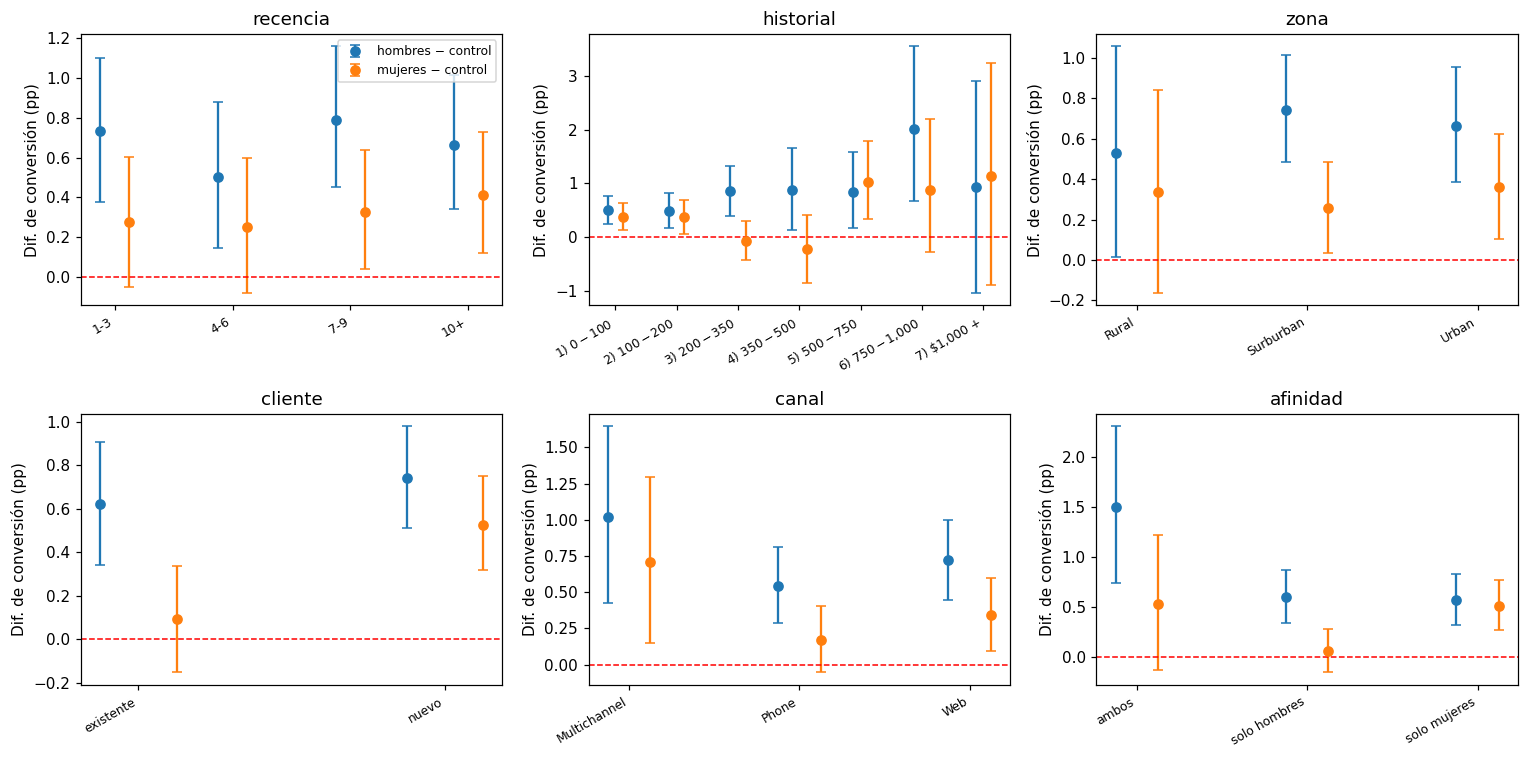

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, var in zip(axes.ravel(), VARIABLES_SEG):
    t = seg_conv[seg_conv["variable"] == var].reset_index(drop=True)
    pos = np.arange(len(t))
    for k, (clave, color, lab) in enumerate([("hom−con", "tab:blue", "hombres − control"), ("muj−con", "tab:orange", "mujeres − control")]):
        y = t[f"dif_{clave}_pp"]
        ax.errorbar(pos + (k - 0.5) * 0.25, y,
                    yerr=[y - t[f"ic_bajo_{clave}"], t[f"ic_alto_{clave}"] - y],
                    fmt="o", capsize=3, color=color, label=lab)
    ax.axhline(0, color="red", linestyle="--", linewidth=1)
    ax.set_xticks(pos)
    ax.set_xticklabels(t["segmento"], rotation=30, ha="right", fontsize=8)
    ax.set_title(var)
    ax.set_ylabel("Dif. de conversión (pp)")
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [13]:
cols = ["variable", "segmento", "n_control", "tasa_control_%", "tasa_hombres_%", "tasa_mujeres_%",
        "dif_hom−con_pp", "dif_muj−con_pp", "dif_hom−muj_pp"]
seg_conv[cols].round(3)

,variable,segmento,n_control,tasa_control_%,tasa_hombres_%,tasa_mujeres_%,dif_hom−con_pp,dif_muj−con_pp,dif_hom−muj_pp
0,recencia,1-3,7438,0.901,1.633,1.176,0.733,0.275,0.458
1,recencia,4-6,4766,0.546,1.049,0.799,0.503,0.254,0.249
2,recencia,7-9,4699,0.340,1.131,0.670,0.790,0.329,0.461
3,recencia,10+,4403,0.295,0.960,0.708,0.665,0.413,0.253
4,historial,1) $0 - $100,7612,0.420,0.919,0.799,0.499,0.379,0.120
5,historial,2) $100 - $200,4836,0.414,0.895,0.783,0.482,0.369,0.113
6,historial,3) $200 - $350,4044,0.692,1.540,0.626,0.848,-0.067,0.915
7,historial,4) $350 - $500,2124,1.130,2.003,0.914,0.873,-0.216,1.089
8,historial,5) $500 - $750,1652,0.545,1.378,1.564,0.833,1.020,-0.187
9,historial,"6) $750 - $1,000",622,0.482,2.484,1.349,2.002,0.867,1.135


### 6.3 Efecto sobre la visita según la afinidad

La prueba de heterogeneidad sobre la visita (sección 6.1) detecta una variación muy marcada según la afinidad del cliente. Se muestra el efecto de cada email sobre la **visita** en cada grupo de afinidad. Es un hallazgo exploratorio: la afinidad era una de las seis variables de segmentación definidas de antemano y el resultado se mantiene tras la corrección de Holm, pero la visita es un paso intermedio y no equivale a ingresos.

In [14]:
afin_visit = efectos_por_segmento("afinidad", "visit")
afin_visit[["segmento", "n_control", "tasa_control_%", "tasa_hombres_%", "tasa_mujeres_%",
            "dif_hom−con_pp", "dif_muj−con_pp", "dif_hom−muj_pp"]].round(3)

,segmento,n_control,tasa_control_%,tasa_hombres_%,tasa_mujeres_%,dif_hom−con_pp,dif_muj−con_pp,dif_hom−muj_pp
0,ambos,2149,18.055,31.499,25.165,13.444,7.110,6.334
1,solo hombres,9638,9.981,16.897,11.089,6.916,1.108,5.808
2,solo mujeres,9519,9.581,16.639,16.979,7.058,7.399,-0.341


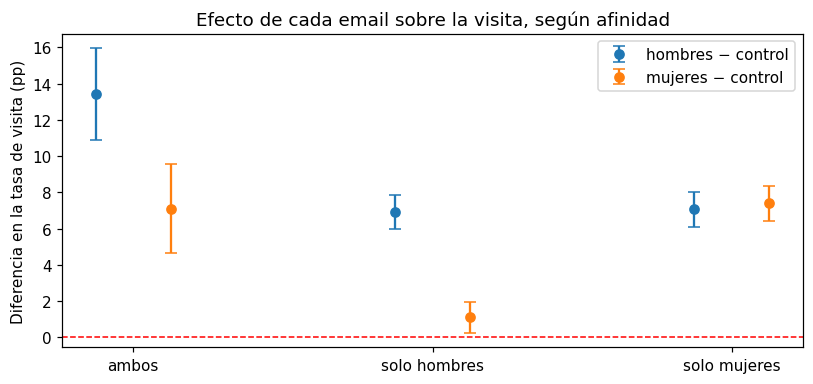

In [15]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
pos = np.arange(len(afin_visit))
for k, (clave, color, lab) in enumerate([("hom−con", "tab:blue", "hombres − control"),
                                         ("muj−con", "tab:orange", "mujeres − control")]):
    y = afin_visit[f"dif_{clave}_pp"]
    ax.errorbar(pos + (k - 0.5) * 0.25, y,
                yerr=[y - afin_visit[f"ic_bajo_{clave}"], afin_visit[f"ic_alto_{clave}"] - y],
                fmt="o", capsize=4, color=color, label=lab)
ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.set_xticks(pos)
ax.set_xticklabels(afin_visit["segmento"])
ax.set_ylabel("Diferencia en la tasa de visita (pp)")
ax.set_title("Efecto de cada email sobre la visita, según afinidad")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Guardar resultados

Las tablas del notebook se guardan en `reports/`: comparaciones bayesianas (`resultados_bayesiano.csv` y `resultados_bayesiano_gasto.csv`), efectos por segmento (`efectos_por_segmento.csv`), pruebas de heterogeneidad (`heterogeneidad.csv`) y el efecto sobre la visita según la afinidad (`afinidad_visita.csv`).

In [16]:
pd.concat([bayes_conv, bayes_visit], ignore_index=True).to_csv(
    os.path.join(ROOT, "reports", "resultados_bayesiano.csv"), index=False)
bayes_gasto.to_csv(os.path.join(ROOT, "reports", "resultados_bayesiano_gasto.csv"), index=False)
seg_conv.to_csv(os.path.join(ROOT, "reports", "efectos_por_segmento.csv"), index=False)
afin_visit.to_csv(os.path.join(ROOT, "reports", "afinidad_visita.csv"), index=False)
het.to_csv(os.path.join(ROOT, "reports", "heterogeneidad.csv"), index=False)
print("Resultados guardados en reports/")

Resultados guardados en reports/


## 8. Conclusiones

- **Conversión (bayesiano):** el email para hombres eleva la conversión en 0,68 pp respecto del control (intervalo de credibilidad 95 %: 0,50 a 0,86) y el de mujeres en 0,31 pp (0,15 a 0,47). La diferencia entre emails es de 0,37 pp a favor del de hombres (0,17 a 0,57). La probabilidad de superioridad es mayor a 99,9 % en las tres comparaciones, y la probabilidad de que la diferencia supere 0,22 pp (el efecto mínimo detectable del notebook 02) es de 100 %, 87 % y 93 %.
- **Decisión entre emails:** elegir el email para hombres tiene una pérdida esperada de prácticamente 0 pp de conversión; elegir el de mujeres, de 0,37 pp.
- **Sensibilidad al prior:** con un prior uniforme, el de Jeffreys y uno informativo centrado en 0,6 %, la mediana de la diferencia hombres − mujeres va de 0,353 a 0,369 pp y la probabilidad de superioridad es de 99,99 % o más. Con 21.000 clientes por grupo los datos dominan y las conclusiones no dependen del prior.
- **Visita:** la probabilidad de superioridad es de 100 % en las tres comparaciones, con diferencias de 7,7 pp (hombres − control), 4,5 pp (mujeres − control) y 3,1 pp (hombres − mujeres).
- **Gasto por cliente (bootstrap bayesiano):** el email para hombres suma 0,77 dólares por cliente frente al control (0,49 a 1,06) y el de mujeres, 0,42 (0,17 a 0,69). La ventaja de hombres sobre mujeres es de 0,34 dólares (0,03 a 0,66), con una probabilidad de superioridad de 98,5 %. La pérdida esperada de elegir el email para mujeres es de 0,35 dólares por cliente, contra 0,001 si se elige el de hombres. Los resultados difieren del análisis frecuentista en menos de 0,01 dólares.
- **Heterogeneidad en conversión:** ninguna de las 18 pruebas Q de Cochran es significativa tras la corrección de Holm (el menor p-valor ajustado es 0,15). Cinco de los 18 p-valores crudos son menores a 0,05, más de lo esperable por azar, pero la prueba tiene poca potencia con eventos raros, de modo que no se puede concluir ni que el efecto sea homogéneo ni que varíe.
- **Heterogeneidad en visita (afinidad, sección 6.3):** el efecto de los emails sobre la visita varía según la afinidad del cliente (p ajustado ≤ 0,0001 en las tres comparaciones; la afinidad era una de las seis variables definidas de antemano). Entre quienes solo compraron productos de hombres, el email para mujeres eleva la visita solo +1,1 pp (de 10,0 % a 11,1 %), contra +7,4 pp entre quienes solo compraron productos de mujeres (de 9,6 % a 17,0 %). El email para hombres funciona en todos los grupos (+6,9 pp, +7,1 pp y +13,4 pp) y entre quienes solo compraron productos de mujeres rinde igual que el de mujeres (−0,3 pp de diferencia). Los clientes que compraron ambos tipos de productos son los más receptivos: tienen la tasa de visita más alta sin email (18,1 %) y los mayores efectos. En conversión, el patrón apunta en la misma dirección (+0,06 pp del email para mujeres entre quienes solo compraron productos de hombres, contra +0,51 pp entre quienes solo compraron productos de mujeres), pero la prueba de heterogeneidad no fue significativa. Es un hallazgo exploratorio que sugiere probar, en un experimento nuevo, no enviar el email para mujeres a quienes solo compraron productos de hombres.
- **Patrones descriptivos en conversión (exploratorios):** el email para hombres tiene efecto positivo en los 22 segmentos (de +0,48 a +2,00 pp). El de mujeres es positivo en casi todos, con efectos entre 0,06 y 1,13 pp, salvo en dos tramos de historial de gasto ($200 a $500), donde el efecto es de −0,07 y −0,22 pp. Entre los clientes que compraron solo productos de hombres, el email para mujeres rinde +0,06 pp, contra +0,51 pp entre los que compraron solo productos de mujeres. La conversión del control baja de 0,90 % (recencia de 1 a 3 meses) a 0,30 % (10 meses o más); el efecto absoluto del email para hombres es parecido en todos los tramos (0,50 a 0,79 pp), por lo que el aumento relativo es mayor en clientes menos recientes.
- **Limitaciones del análisis por segmentos:** es exploratorio y sirve para generar hipótesis. Hay segmentos con muy pocas compras (por ejemplo, el control del tramo de historial de $750 a $1.000 tiene 622 clientes y unas 3 compras), por lo que sus intervalos son muy amplios y no deben interpretarse. Saber a qué clientes conviene enviar cada email requeriría un modelo de uplift, que excede este análisis.
- **Limitaciones generales:** ingreso bruto sin costos ni márgenes, seguimiento de solo dos semanas, muestra de clientes que compraron en los últimos 12 meses, y los dos emails difieren en contenido y audiencia a la vez.